# General Settings

In [785]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("future.no_silent_downcasting", True)

# Import and Load
Load the raw data from the *Parametric Analysis* Sheet of an Excel file into a Pandas Data Frame using the Openpyxl engine. Überspringe die ersten beiden Zeilen des Excel Sheets, da diese sowieso keine relevanten Information enthalten

In [786]:
raw_data_path = os.path.join(
    os.path.dirname(os.getcwd()), "data", "raw", "MCDI_Overview_10-04-2025.xlsx"
)

df = pd.read_excel(
    raw_data_path, sheet_name="Parametric Analysis", engine="calamine", skiprows=2, dtype=str
)

df.head()

,Unnamed: 0,Test #,Mol.\r\n(g/L),H2O\r\n,pH\r\n,Time\r\n(s),Flow\r\n (L/min),Volt. Lim.\r\n(V),Curr. Lim.\r\n(A),Check,EC In \r\n(mS/cm),EC In Dev. (%),EC Pure\r\n(mS/cm),Remov. \r\n(%),SEC \r\n(kWh/m³),Spalte1,Ry \r\n(%),Min EC Pure (mS/cm),Max. Remov. (%),Avg. EC In (mS/cm),Avg. EC Pure (mS/cm),pH Pure,pH Conc.,Test Remarks,Unnamed: 24,Unnamed: 25
0,0 - General Tests,0.1,1,DI,-,95/15/80,"0,45/0,5/0,5","1,95/1,5/1,5",60/50/55,Valid,4.42,0.014712438698172054,1.28,71,-,NaN,40,0.082,98.1,4.06,0.09,-,-,Met all the criterias.,NaN,NaN
1,NaN,0.2,1,DI,-,95/15/80,"0,35/0,4/0,4","1,95/1,5/1,5",60/50/55,Valid,4.21,0.06152474364690143,1.82,57,-,NaN,41,0.134,96.8,4.15,0.16,-,-,NaN,NaN,NaN
2,NaN,0.3,1,DI,-,95/15/80,"0,3/0,3/0,3","1,95/1,5/1,5",60/50/55,Valid,4.15,0.07489968791796688,2.36,43,-,NaN,37,0.202,95.1,4.11,0.24,-,-,NaN,NaN,NaN
3,NaN,0.4,1,DI,-,95/15/80,"0,25/0,25/0,25","1,95/1,5/1,5",60/50/55,Valid,4.13,0.07935800267498883,2.98,28,13.81,0.08312816799420708,41,0.285,93.1,4.1,0.29,-,-,NaN,NaN,NaN
4,NaN,0.5,1,DI,-,95/15/80,"0,25/0,25/0,25","1,9/1,9/1,9",60/50/55,Valid,4.11,0.08381631743201058,3.08,25,-,NaN,37,0.285,93.1,4.08,0.3,-,-,NaN,NaN,NaN


# Clean

## Basic steps

Wie man sehen kann ist das eingelesene Dataframe durch das Exportieren aus der für Menschen gut lesbaren Excel Datei ziemlich unstrukturiert. Daher muss man einige Schritte vornehmen um das Data Frame in eine verarbeitbare Form zu bringen:

1. Deutsche Bezeichner in englische Bezeichner umbennen und eindeutig Bezeichner einsetzen
2. Undefinierte Spalten löschen
3. Jede Messung einer Messreihe zuordnen
4. Validity Spalte als erste Daten-Spalten definieren, damit man schnell sieht, ob ein Datenpunkt eine valide Messung darstellt

In [787]:
# Local helper function
def move_column(df, col_name, new_position):
    cols = list(df.columns)
    cols.insert(new_position, cols.pop(cols.index(col_name)))
    return df[cols]

# 1. Rename columns
df.rename(
    columns={
        "Unnamed: 0": "Series",
        "Test #": "Measurement",
        "Mol.\r\n(g/L)": "Molarity (g/l)",
        "H2O\r\n": "Water Type",
        "pH\r\n": "pH-Level (pH)",
        "Time\r\n(s)": "Time (s)",
        "Flow\r\n (L/min)": "Flow (l/min)",
        "Volt. Lim.\r\n(V)": "Voltage Limit (V)",
        "Curr. Lim.\r\n(A)": "Current Limit (A)",
        "Check": "Validity",
        "EC In \r\n(mS/cm)": "Undefined", #TODO: Add correct identifier
        "EC In Dev. (%)": "Undefined", #TODO: Add correct identifier
        "EC Pure\r\n(mS/cm)": "Undefined", #TODO: Add correct identifier
        "Remov. \r\n(%)": "Average CO2 Removal (%)",
        "SEC \r\n(kWh/m³)": "Undefined",
        "Spalte1": "Undefined", #TODO: Add correct identifier
        "Ry \r\n(%)": "Average Water Recovery (%)",
        "Min EC Pure (mS/cm)": "Undefined", #TODO: Add correct identifier
        "Max. Remov. (%)": "Maximum CO2 Removal (%)",
        "Avg. EC In (mS/cm)": "Undefined", #TODO: Add correct identifier
        "Avg. EC Pure (mS/cm)": "Undefined", #TODO: Add correct identifier
        "pH Pure": "Undefined", #TODO: Add correct identifier
        "pH Conc. ": "Undefined", #TODO: Add correct identifier
        "Test Remarks ": "Undefined",
        "Unnamed: 24": "Undefined",
        "Unnamed: 25": "Undefined",
    },
    inplace=True,
)

# 2. Delete columns that are undefined
df.drop(columns=["Undefined"], inplace=True)
df.drop(df.tail(2).index,inplace=True)

# 3. Fill Series column
df["Series"] = df["Series"].ffill()

# 4. Move Check column to be the third column
df = move_column(df, "Validity", 2)

df.head()

,Series,Measurement,Validity,Molarity (g/l),Water Type,pH-Level (pH),Time (s),Flow (l/min),Voltage Limit (V),Current Limit (A),Average CO2 Removal (%),Average Water Recovery (%),Maximum CO2 Removal (%)
0,0 - General Tests,0.1,Valid,1,DI,-,95/15/80,"0,45/0,5/0,5","1,95/1,5/1,5",60/50/55,71,40,98.1
1,0 - General Tests,0.2,Valid,1,DI,-,95/15/80,"0,35/0,4/0,4","1,95/1,5/1,5",60/50/55,57,41,96.8
2,0 - General Tests,0.3,Valid,1,DI,-,95/15/80,"0,3/0,3/0,3","1,95/1,5/1,5",60/50/55,43,37,95.1
3,0 - General Tests,0.4,Valid,1,DI,-,95/15/80,"0,25/0,25/0,25","1,95/1,5/1,5",60/50/55,28,41,93.1
4,0 - General Tests,0.5,Valid,1,DI,-,95/15/80,"0,25/0,25/0,25","1,9/1,9/1,9",60/50/55,25,37,93.1


## Split columns with multiple values

5. Die Spalten Time, Flow, Voltage Limit und Current Limit geben je insgesamt 3 Werte für 3 verschiedene Phasen an. Diese Werte werden jetzt auf 3 seperate Spalten aufgeteilt (Concentrate - C, Pre-Purify - PP, Purify - P), um die Werte später besser verarbeiten zu können 
6. Die Schreibweise von Werten, die ein Komma beinhalten, wird auf die Punkt-Schreibweise geändert

In [788]:
# Local helper function
def split_column(df, column_name, new_column_names, separator):
    df[new_column_names] = df[column_name].str.split(separator, expand=True)
    df.drop(columns=column_name, inplace=True)
    return df

# 5. Split columns with multiple values
df = split_column(df, "Time (s)", ["Time_C (s)", "Time_PP (s)", "Time_P (s)"], "/")
df = split_column(df, "Flow (l/min)", ["Flow_C (l/min)", "Flow_PP (l/min)", "Flow_P (l/min)"], "/")
df = split_column(df, "Voltage Limit (V)", ["Voltage_Limit_C (V)", "Voltage_Limit_PP (V)", "Voltage_Limit_P (V)"], "/")
df = split_column(df, "Current Limit (A)", ["Current_Limit_C (A)", "Current_Limit_PP (A)", "Current_Limit_P (A)"], "/")

# 6. Replace commas with dots in object columns
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.replace(',', '.', regex=False)

display( df.head(3) )
display( df.dtypes )

,Series,Measurement,Validity,Molarity (g/l),Water Type,pH-Level (pH),Average CO2 Removal (%),Average Water Recovery (%),Maximum CO2 Removal (%),Time_C (s),Time_PP (s),Time_P (s),Flow_C (l/min),Flow_PP (l/min),Flow_P (l/min),Voltage_Limit_C (V),Voltage_Limit_PP (V),Voltage_Limit_P (V),Current_Limit_C (A),Current_Limit_PP (A),Current_Limit_P (A)
0,0 - General Tests,0.1,Valid,1,DI,-,71,40,98.1,95,15,80,0.45,0.5,0.5,1.95,1.5,1.5,60,50,55
1,0 - General Tests,0.2,Valid,1,DI,-,57,41,96.8,95,15,80,0.35,0.4,0.4,1.95,1.5,1.5,60,50,55
2,0 - General Tests,0.3,Valid,1,DI,-,43,37,95.1,95,15,80,0.3,0.3,0.3,1.95,1.5,1.5,60,50,55


Series                        object
Measurement                   object
Validity                      object
Molarity (g/l)                object
Water Type                    object
pH-Level (pH)                 object
Average CO2 Removal (%)       object
Average Water Recovery (%)    object
Maximum CO2 Removal (%)       object
Time_C (s)                    object
Time_PP (s)                   object
Time_P (s)                    object
Flow_C (l/min)                object
Flow_PP (l/min)               object
Flow_P (l/min)                object
Voltage_Limit_C (V)           object
Voltage_Limit_PP (V)          object
Voltage_Limit_P (V)           object
Current_Limit_C (A)           object
Current_Limit_PP (A)          object
Current_Limit_P (A)           object
dtype: object

## Set correct Data Types

Man sieht hier, dass noch einige Spalten vom Typ "object" sind, was für eine mathematische Verarbeitung ungeeignet ist.

7. Um die richtigen Datentypen für die Spalten setzen zu können, muss man zunächst alle nicht existierenden Werte auf "Not a Number" setzen.
8. Als letzten Schritt der Clean-Phase werden noch alle Datentypen sinnvoll gewählt

In [789]:
# Local helper list
except_columns = [
    "Series",
    "Measurement",
    "Water Type",
    "Validity",
]

# 7. Replace non-existing values with NaN
df.replace('-', np.nan, inplace=True)
df.replace('', np.nan, inplace=True)

# 8. Set correct data types
cols = df.select_dtypes(include='object').columns
cols = cols.drop(except_columns)
df[cols] = df[cols].astype("float")

display( df.head(3) )
display( df.info() )

,Series,Measurement,Validity,Molarity (g/l),Water Type,pH-Level (pH),Average CO2 Removal (%),Average Water Recovery (%),Maximum CO2 Removal (%),Time_C (s),Time_PP (s),Time_P (s),Flow_C (l/min),Flow_PP (l/min),Flow_P (l/min),Voltage_Limit_C (V),Voltage_Limit_PP (V),Voltage_Limit_P (V),Current_Limit_C (A),Current_Limit_PP (A),Current_Limit_P (A)
0,0 - General Tests,0.1,Valid,1.0,DI,NaN,71.0,40.0,98.1,95.0,15.0,80.0,0.45,0.5,0.5,1.95,1.5,1.5,60.0,50.0,55.0
1,0 - General Tests,0.2,Valid,1.0,DI,NaN,57.0,41.0,96.8,95.0,15.0,80.0,0.35,0.4,0.4,1.95,1.5,1.5,60.0,50.0,55.0
2,0 - General Tests,0.3,Valid,1.0,DI,NaN,43.0,37.0,95.1,95.0,15.0,80.0,0.30,0.3,0.3,1.95,1.5,1.5,60.0,50.0,55.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Series                      65 non-null     object 
 1   Measurement                 65 non-null     object 
 2   Validity                    65 non-null     object 
 3   Molarity (g/l)              65 non-null     float64
 4   Water Type                  65 non-null     object 
 5   pH-Level (pH)               47 non-null     float64
 6   Average CO2 Removal (%)     65 non-null     float64
 7   Average Water Recovery (%)  65 non-null     float64
 8   Maximum CO2 Removal (%)     65 non-null     float64
 9   Time_C (s)                  65 non-null     float64
 10  Time_PP (s)                 65 non-null     float64
 11  Time_P (s)                  65 non-null     float64
 12  Flow_C (l/min)              65 non-null     float64
 13  Flow_PP (l/min)             65 non-nu

None

# Incorporate Expertise

An dieser Stelle wird gezielt Fachwissen des leitenden Doktoranten der Anlage und seines Teams eingesetzt, um bestimmte Datenpunkte gezielt auszuschließen, damit die Ergebnisse nicht durch fehlerhafte Werte verfälscht werden.

Folgende Messungen werden ausgeschlossen:
1. Alle als invalide gekennzeichnete Messwerte
2. Messungen deren Molarität in g/l unter 0.5 liegt
3. Solche Messungen bei denen kein destiliertes Wasser verwendet wurde
4. Die Gesamte 4. Messreihe, da in dieser Reihe Fehler beim Einstellen des ph Wertes passiert sind
5. Alle Messungen, deren Phasen-Zeiten von 155/45/120 abweichen, da sonst die Vergleichbarkeit der Messungen verloren geht

In [790]:
print("Dataframe shape before filtering:")
display(df.shape[0])

# 1. Drop all measurements that are not valid
df = df[df["Validity"] == "Valid"]

# 2. Drop all measurements with Mol.\n(g/L) unequal to 0.5
df = df[df["Molarity (g/l)"] == 0.5]

# 3. Drop all measurements with H2O unequal to DI
df = df[df["Water Type"] == "DI"]

# 4. Drop the 4th measurement series
df = df[df["Series"] != "4 -  pH Series"]

# 5. Drop all measurements with a time in seconds unequal to 155/45/120
df = df[df["Time_C (s)"] == 155]
df = df[df["Time_PP (s)"] == 45]
df = df[df["Time_P (s)"] == 120]

print("Dataframe shape after filtering:")
display(df.shape[0])

Dataframe shape before filtering:


65

Dataframe shape after filtering:


26

Wie man hier sehen kann, reduziert sich die Anzahl an Datenpunkten durch den Einfluss von Fachwissen über die Experimente drastisch von zuvor 65 Datenpunkten auf gerade einmal 26.

# Transform

In diesem Schritt werden die Daten so transformiert, dass eine beste mögliche Vergleichbarkeit gewähleistet werden kann. Dafür werden die Daten zunächste normalisiert:
1. One Hot Encoding für alle kategorischen Features (hier nur der Water Type)
3. Nan-Werte der Spalte pH-Level mit dem Mittelwert der restlichen Werte aus der Spalte ersetzen
2. Min-Max Normalisierung für alle Werte außer pronztentuale Angaben
4. Drop Duplicates in case there are any

Je nach Verwendung könnte an dieser Stelle in der Zukunft auch eine Standardisierung notwendig/sinnvoll sein, wenn beispielsweise Gradient-based Algorithms eingesetzt werden.

In [791]:
# Local helper lists
normalize_columns_min_max = [
    "Molarity (g/l)",
    "pH-Level (pH)",
    "Time_C (s)",
    "Time_PP (s)",
    "Time_P (s)",
    "Flow_C (l/min)",
    "Flow_PP (l/min)",
    "Flow_P (l/min)",
    "Voltage_Limit_C (V)",
    "Voltage_Limit_PP (V)",
    "Voltage_Limit_P (V)",
    "Current_Limit_C (A)",
    "Current_Limit_PP (A)",
    "Current_Limit_P (A)"
]
normalize_columns_percentage = [
    "Average CO2 Removal (%)",
    "Average Water Recovery (%)",
    "Maximum CO2 Removal (%)"
]

# 1. One Hot Encoding for Water Type feature
one_hot_water_type = pd.get_dummies(df["Water Type"])
df = pd.concat([df, one_hot_water_type], axis=1)
df = df.drop(columns = ["Water Type"])

# 2. Fill NaN values in pH-Level column with mean of the column
ph_level_mean = df["pH-Level (pH)"].mean()
df["pH-Level (pH)"] = df["pH-Level (pH)"].fillna(ph_level_mean)

# 3. Min-Max Normalization for all columns except percentage columns
scaler = MinMaxScaler()
df[normalize_columns_min_max] = scaler.fit_transform(df[normalize_columns_min_max])

# 4. Normalize percentage columns
df[normalize_columns_percentage] = df[normalize_columns_percentage].clip(0, 100) / 100

# 5. Drop Duplicates
df.drop_duplicates(inplace=True)

df.head()

,Series,Measurement,Validity,Molarity (g/l),pH-Level (pH),Average CO2 Removal (%),Average Water Recovery (%),Maximum CO2 Removal (%),Time_C (s),Time_PP (s),Time_P (s),Flow_C (l/min),Flow_PP (l/min),Flow_P (l/min),Voltage_Limit_C (V),Voltage_Limit_PP (V),Voltage_Limit_P (V),Current_Limit_C (A),Current_Limit_PP (A),Current_Limit_P (A),DI
10,1 - Pre-Optimization 0.5,1.1,Valid,0.0,0.56381,0.96,0.36,0.982,0.0,0.0,0.0,0.4,0.454545,0.454545,0.0,0.0,0.0,1.0,1.0,1.0,True
11,1 - Pre-Optimization 0.5,1.2,Valid,0.0,0.56381,0.95,0.36,0.977,0.0,0.0,0.0,0.2,0.272727,0.272727,0.0,0.0,0.0,1.0,1.0,1.0,True
12,1 - Pre-Optimization 0.5,1.3,Valid,0.0,0.56381,0.89,0.34,0.966,0.0,0.0,0.0,0.1,0.090909,0.090909,0.0,0.0,0.0,1.0,1.0,1.0,True
13,1 - Pre-Optimization 0.5,1.4,Valid,0.0,0.56381,0.83,0.33,0.956,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,1.0,1.0,1.0,True
14,1 - Pre-Optimization 0.5,1.5,Valid,0.0,0.56381,0.97,0.36,0.985,0.0,0.0,0.0,0.6,0.636364,0.636364,0.0,0.0,0.0,1.0,1.0,1.0,True


# Restructure

Nun werden die Input Daten in ein eigenes Date Frame verpack, um sie dann im Anschluss analysieren und für die weitere Verarbeitung exportieren zu können. Die Ausgangsdaten Removal und Recovery werden ebenfalls in ein eigenes Data Frame gespeichert.

In [792]:
df_input_data = df[["Series", "Measurement", "Flow_C (l/min)", "Flow_PP (l/min)", "Flow_P (l/min)", "Current_Limit_P (A)"]]

df_output_data_avg_removal = df[["Series", "Measurement", "Average CO2 Removal (%)"]]
df_output_data_avg_recovery = df[["Series", "Measurement", "Average Water Recovery (%)"]]

# Validate

todo

<Axes: >

array([[<Axes: title={'center': 'Flow_C (l/min)'}>,
        <Axes: title={'center': 'Flow_PP (l/min)'}>],
       [<Axes: title={'center': 'Flow_P (l/min)'}>,
        <Axes: title={'center': 'Current_Limit_P (A)'}>]], dtype=object)

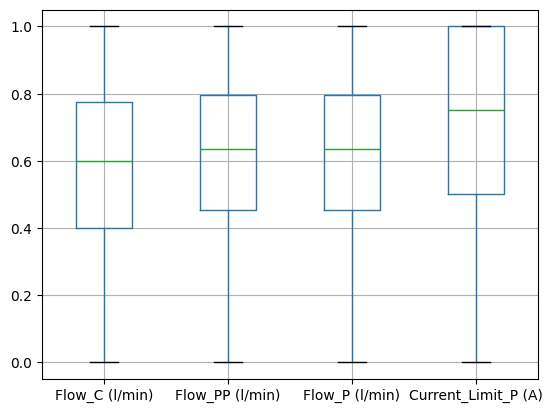

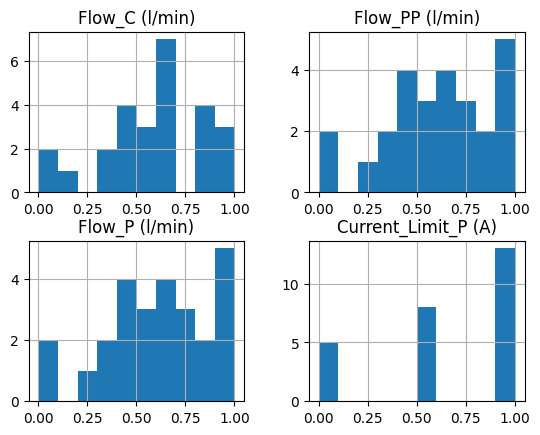

In [793]:
#TODO: do

display(input_data.boxplot())
display(input_data.hist())

# Save

Im letzten Schritt müssen die Eingabedaten und Ausgangsdaten noch exportiert werden, um sie in der Modellierung und Optimierung wiederverwenden zu können.
Die Daten werden im .csv Format exportiert, da man sie besonders einfach wieder einlesen kann. Am Ende wird noch einmal überprüft, ob die Daten korrekt exportiert wurden, in dem sie einmal zurück eingelesen werden.

In [794]:
processed_data_path = os.path.join(os.path.dirname(os.getcwd()), "data", "processed")
input_data_path = os.path.join(os.path.dirname(os.getcwd()), "data", "processed", "input_data.csv")
output_data_avg_removal_path = os.path.join(os.path.dirname(os.getcwd()), "data", "processed", "output_data_avg_removal.csv")
output_data_avg_recovery_path = os.path.join(os.path.dirname(os.getcwd()), "data", "processed", "output_data_avg_recovery.csv")

df_input_data.to_csv(input_data_path, index=False)
df_output_data_avg_removal.to_csv(output_data_avg_removal_path, index=False)
df_output_data_avg_recovery.to_csv(output_data_avg_recovery_path, index=False)

In [796]:
df_read_back_input = pd.read_csv(input_data_path)
df_read_back_output_avg_removal = pd.read_csv(output_data_avg_removal_path)
df_read_back_output_avg_recovery = pd.read_csv(output_data_avg_recovery_path)

display(df_read_back_input.head(3))
display(df_read_back_output_avg_removal.head(3))
display(df_read_back_output_avg_recovery.head(3))

,Series,Measurement,Flow_C (l/min),Flow_PP (l/min),Flow_P (l/min),Current_Limit_P (A)
0,1 - Pre-Optimization 0.5,1.1,0.4,0.454545,0.454545,1.0
1,1 - Pre-Optimization 0.5,1.2,0.2,0.272727,0.272727,1.0
2,1 - Pre-Optimization 0.5,1.3,0.1,0.090909,0.090909,1.0


,Series,Measurement,Average CO2 Removal (%)
0,1 - Pre-Optimization 0.5,1.1,0.96
1,1 - Pre-Optimization 0.5,1.2,0.95
2,1 - Pre-Optimization 0.5,1.3,0.89


,Series,Measurement,Average Water Recovery (%)
0,1 - Pre-Optimization 0.5,1.1,0.36
1,1 - Pre-Optimization 0.5,1.2,0.36
2,1 - Pre-Optimization 0.5,1.3,0.34
